# Практичне завдання 1
## Лінійна регресія, оптимізація та статистичний аналіз

**Виконав:** Новак Сергій, ФЕІ-43с

### Мета

Побудувати повний і відтворюваний процес навчання лінійної регресії: від EDA та
підготовки даних без витоку інформації до власної NumPy-реалізації Batch GD,
SGD і Mini-batch GD, оцінювання $R^2$ та перевірки статистичних припущень.

### Дані

Використано Kaggle-версію **Ames Housing**: 1460 будинків, 79 пояснювальних
ознак, ідентифікатор `Id` та ціль `SalePrice`.

- офіційна сторінка: https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data
- локальний файл: `data/ames_housing.csv`
- публічне дзеркало, з якого збережено CSV: https://github.com/Ayeshaa-Aslam/House-Prices-Advanced-Regression-Techniques

> Важливий принцип роботи: спочатку виконується розбиття Train/Validation/Test,
> і лише потім на Train навчаються відбір ознак, імпутація, кодування та
> масштабування. Test використовується тільки для фінального оцінювання.

In [1]:
from pathlib import Path
from time import perf_counter
import os
import tempfile
import warnings

import numpy as np
import pandas as pd

matplotlib_cache = Path(tempfile.gettempdir()) / "ml1-matplotlib-cache"
matplotlib_cache.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(matplotlib_cache)

import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11})
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

## 1. Завантаження та первинний аналіз даних (EDA)

Спочатку перевіряємо розмір, типи стовпців, дублікати, пропущені значення та
описові статистики. `Id` є лише ідентифікатором і не має змісту як предиктор.

In [2]:
DATA_PATH = Path("data/ames_housing.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Не знайдено data/ames_housing.csv. Запускайте notebook з кореня репозиторію."
    )

df = pd.read_csv(DATA_PATH)
required_columns = {"Id", "SalePrice", "GrLivArea", "YearBuilt", "Neighborhood"}
assert required_columns.issubset(df.columns), "CSV не відповідає Ames Housing"
assert df["SalePrice"].notna().all(), "Цільова змінна не повинна мати пропусків"

numeric_count = df.select_dtypes(include=np.number).shape[1]
categorical_count = df.select_dtypes(exclude=np.number).shape[1]

print(f"Файл: {DATA_PATH.as_posix()}")
print(f"Розмір: {df.shape[0]} рядків × {df.shape[1]} стовпців")
print(f"Числових стовпців: {numeric_count}; категоріальних: {categorical_count}")
print(f"Повних дублікатів: {df.duplicated().sum()}")
display(df.head(3))

Файл: data/ames_housing.csv
Розмір: 1460 рядків × 81 стовпців
Числових стовпців: 38; категоріальних: 43
Повних дублікатів: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.000,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.000",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.000,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.000",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.000,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.000",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [3]:
key_columns = [
    "SalePrice", "LotArea", "GrLivArea", "OverallQual", "YearBuilt",
    "TotalBsmtSF", "GarageCars", "FullBath"
]
display(df[key_columns].describe().T)

missing = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": 100 * df.isna().mean(),
    })
    .query("missing_count > 0")
    .sort_values("missing_percent", ascending=False)
)
print(f"Стовпців із пропусками: {len(missing)}")
display(missing.head(15))

,count,mean,std,min,25%,50%,75%,max
SalePrice,"1,460.000","180,921.196","79,442.503","34,900.000","129,975.000","163,000.000","214,000.000","755,000.000"
LotArea,"1,460.000","10,516.828","9,981.265","1,300.000","7,553.500","9,478.500","11,601.500","215,245.000"
GrLivArea,"1,460.000","1,515.464",525.480,334.000,"1,129.500","1,464.000","1,776.750","5,642.000"
OverallQual,"1,460.000",6.099,1.383,1.000,5.000,6.000,7.000,10.000
YearBuilt,"1,460.000","1,971.268",30.203,"1,872.000","1,954.000","1,973.000","2,000.000","2,010.000"
TotalBsmtSF,"1,460.000","1,057.429",438.705,0.000,795.750,991.500,"1,298.250","6,110.000"
GarageCars,"1,460.000",1.767,0.747,0.000,1.000,2.000,2.000,4.000
FullBath,"1,460.000",1.565,0.551,0.000,1.000,2.000,2.000,3.000


Стовпців із пропусками: 19


,missing_count,missing_percent
PoolQC,1453,99.521
MiscFeature,1406,96.301
Alley,1369,93.767
Fence,1179,80.753
MasVnrType,872,59.726
FireplaceQu,690,47.260
LotFrontage,259,17.740
GarageType,81,5.548
GarageYrBlt,81,5.548
GarageFinish,81,5.548


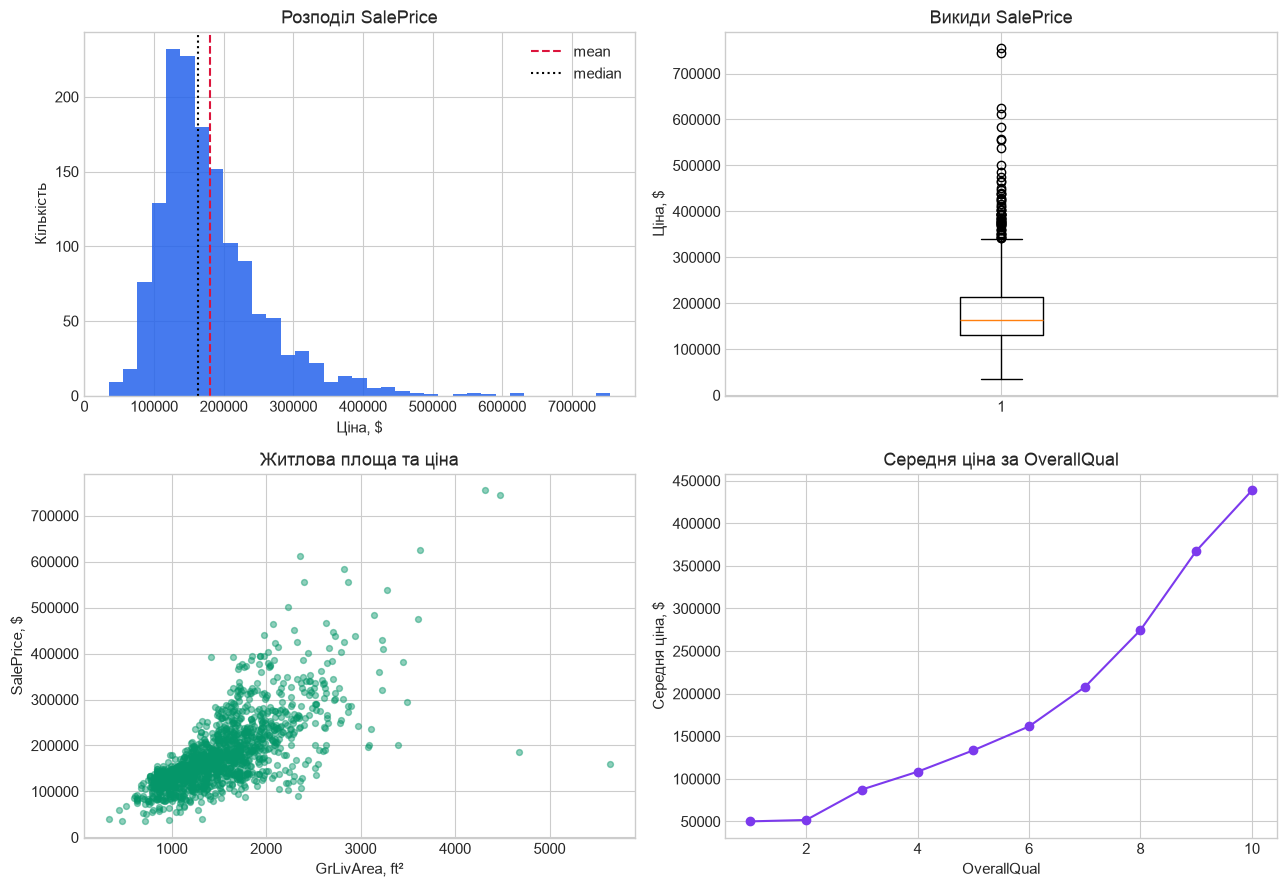

Асиметрія SalePrice (skewness): 1.883
EDA-висновок: SalePrice має правосторонню асиметрію та дорогі об'єкти-викиди; зв'язки з площею й загальною якістю помітні, але не цілком лінійні.


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].hist(df["SalePrice"], bins=35, color="#2563eb", alpha=0.85)
axes[0, 0].axvline(df["SalePrice"].mean(), color="crimson", ls="--", label="mean")
axes[0, 0].axvline(df["SalePrice"].median(), color="black", ls=":", label="median")
axes[0, 0].set(title="Розподіл SalePrice", xlabel="Ціна, $", ylabel="Кількість")
axes[0, 0].legend()

axes[0, 1].boxplot(df["SalePrice"], orientation="vertical")
axes[0, 1].set(title="Викиди SalePrice", ylabel="Ціна, $")

axes[1, 0].scatter(df["GrLivArea"], df["SalePrice"], alpha=0.45, s=18, color="#059669")
axes[1, 0].set(title="Житлова площа та ціна", xlabel="GrLivArea, ft²", ylabel="SalePrice, $")

quality_means = df.groupby("OverallQual")["SalePrice"].mean()
axes[1, 1].plot(quality_means.index, quality_means.values, marker="o", color="#7c3aed")
axes[1, 1].set(title="Середня ціна за OverallQual", xlabel="OverallQual", ylabel="Середня ціна, $")

fig.tight_layout()
plt.show()

print(f"Асиметрія SalePrice (skewness): {df['SalePrice'].skew():.3f}")
print(
    "EDA-висновок: SalePrice має правосторонню асиметрію та дорогі об'єкти-викиди; "
    "зв'язки з площею й загальною якістю помітні, але не цілком лінійні."
)

## 2. Розбиття вибірки до будь-яких навчених перетворень

Використовуємо частки **70% / 15% / 15%**. Валідація потрібна для вибору ознак і
learning rate, а Test — для одноразової чесної оцінки узагальнення.

**Data Leakage** — це потрапляння інформації з Validation/Test або з майбутнього
в процес навчання. Якщо спочатку обчислити медіани, категорії, середні та
масштаби на всіх даних, модель опосередковано «бачить» Test, тому його метрики
стають оптимістичними.

In [5]:
X = df.drop(columns=["SalePrice", "Id"])
y = df["SalePrice"].astype(float)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

split_table = pd.DataFrame(
    {
        "rows": [len(X_train), len(X_val), len(X_test)],
        "share": [len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
    },
    index=["Train", "Validation", "Test"],
)
display(split_table)

,rows,share
Train,1022,0.700
Validation,219,0.150
Test,219,0.150


## 3. Відбір ознак лише на Train

Для числових ознак використовуємо абсолютну кореляцію Пірсона з `SalePrice`.
Беремо вісім найсильніших, а також `YearBuilt` і `LotArea`: перша має зрозумілий
економічний зміст, друга корисна для демонстрації проблем різних масштабів.

Для категоріальних кандидатів обчислюємо **correlation ratio** $\eta^2$ — частку
варіації ціни, пояснену різницею групових середніх. Усі статистики рахуються
виключно на Train.

In [6]:
numeric_candidates = X_train.select_dtypes(include=np.number).columns.tolist()
numeric_correlations = (
    X_train[numeric_candidates]
    .corrwith(y_train)
    .abs()
    .dropna()
    .sort_values(ascending=False)
)

top_numeric = numeric_correlations.head(8).index.tolist()
selected_numeric = list(dict.fromkeys(top_numeric + ["YearBuilt", "LotArea"]))

categorical_candidates = [
    "Neighborhood", "BldgType", "HouseStyle", "KitchenQual",
    "ExterQual", "BsmtQual", "GarageFinish", "SaleCondition",
]

def correlation_ratio_squared(categories, values):
    '''Between-group sum of squares / total sum of squares.'''
    frame = pd.DataFrame({"category": categories.fillna("Missing"), "target": values})
    grouped = frame.groupby("category", observed=False)["target"].agg(["count", "mean"])
    overall_mean = frame["target"].mean()
    ss_between = (grouped["count"] * (grouped["mean"] - overall_mean) ** 2).sum()
    ss_total = ((frame["target"] - overall_mean) ** 2).sum()
    return float(ss_between / ss_total) if ss_total > 0 else 0.0

category_scores = pd.Series(
    {
        column: correlation_ratio_squared(X_train[column], y_train)
        for column in categorical_candidates
    },
    name="eta_squared",
).sort_values(ascending=False)
selected_categorical = category_scores.head(4).index.tolist()

print("Обрані числові ознаки:", selected_numeric)
print("Обрані категоріальні ознаки:", selected_categorical)
display(pd.DataFrame({"abs_corr_with_SalePrice": numeric_correlations.head(12)}))
display(category_scores.to_frame())

Обрані числові ознаки: ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'LotArea']
Обрані категоріальні ознаки: ['Neighborhood', 'BsmtQual', 'KitchenQual', 'ExterQual']


,abs_corr_with_SalePrice
OverallQual,0.785
GrLivArea,0.689
GarageCars,0.643
GarageArea,0.622
TotalBsmtSF,0.590
1stFlrSF,0.583
FullBath,0.549
TotRmsAbvGrd,0.520
YearBuilt,0.512
YearRemodAdd,0.512


,eta_squared
Neighborhood,0.529
BsmtQual,0.455
KitchenQual,0.454
ExterQual,0.440
GarageFinish,0.305
SaleCondition,0.130
HouseStyle,0.084
BldgType,0.040


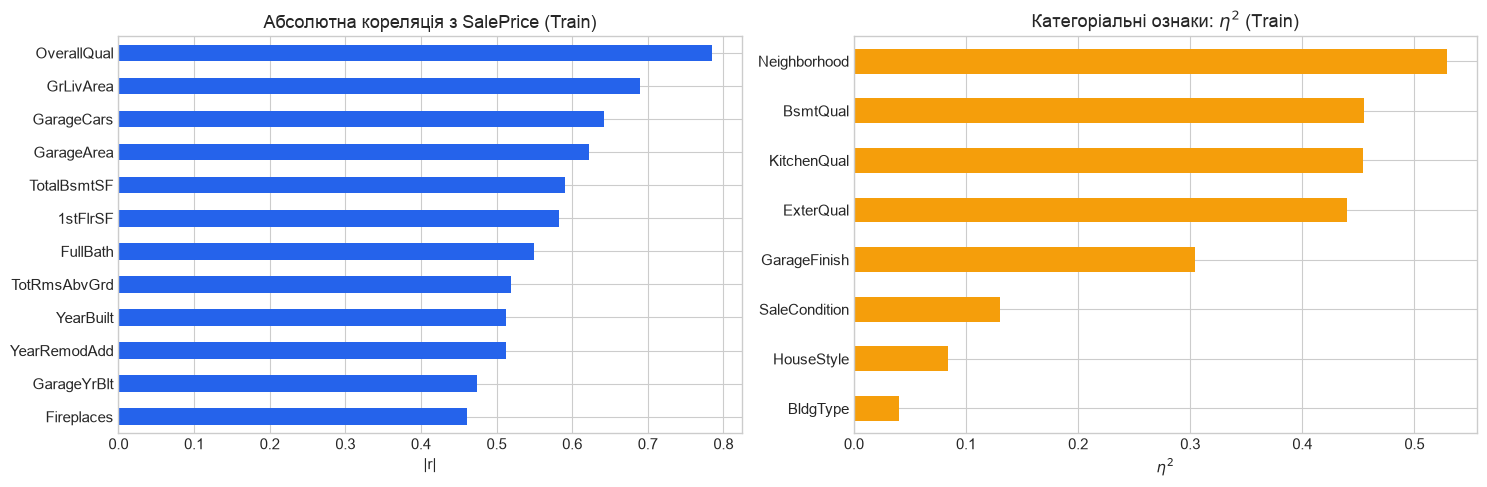

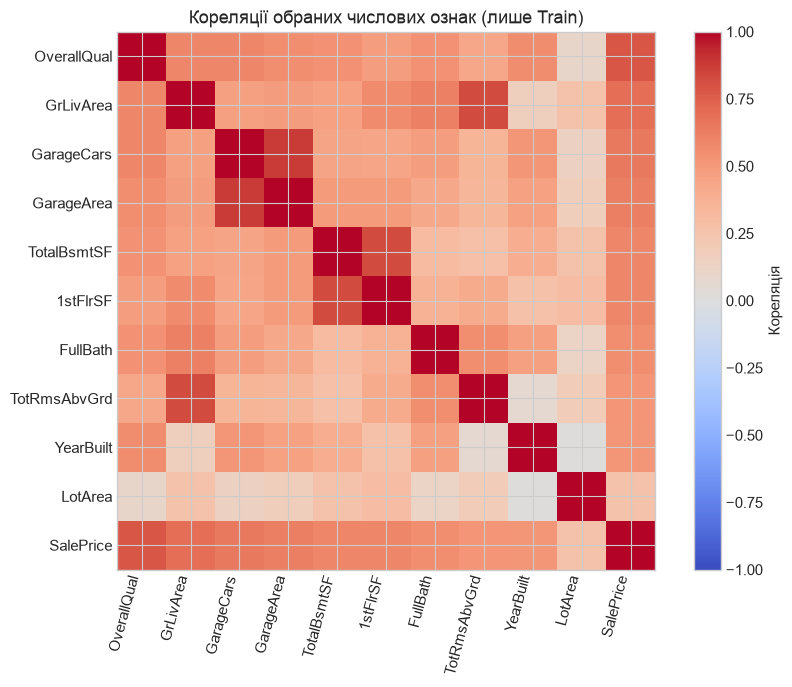

Пари з |r| ≥ 0.75: [('GrLivArea', 'TotRmsAbvGrd', np.float64(0.8229918985711544)), ('GarageCars', 'GarageArea', np.float64(0.8810035219248301)), ('TotalBsmtSF', '1stFlrSF', np.float64(0.826623073412453))]


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

numeric_correlations.head(12).sort_values().plot.barh(ax=axes[0], color="#2563eb")
axes[0].set(title="Абсолютна кореляція з SalePrice (Train)", xlabel="|r|")

category_scores.sort_values().plot.barh(ax=axes[1], color="#f59e0b")
axes[1].set(title=r"Категоріальні ознаки: $\eta^2$ (Train)", xlabel=r"$\eta^2$")
fig.tight_layout()
plt.show()

train_corr = pd.concat(
    [X_train[selected_numeric], y_train.rename("SalePrice")], axis=1
).corr()
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(train_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(train_corr.columns)), train_corr.columns, rotation=75, ha="right")
ax.set_yticks(range(len(train_corr.columns)), train_corr.columns)
fig.colorbar(image, ax=ax, label="Кореляція")
ax.set_title("Кореляції обраних числових ознак (лише Train)")
fig.tight_layout()
plt.show()

strong_pairs = []
for i, first in enumerate(selected_numeric):
    for second in selected_numeric[i + 1:]:
        value = train_corr.loc[first, second]
        if abs(value) >= 0.75:
            strong_pairs.append((first, second, value))
print("Пари з |r| ≥ 0.75:", strong_pairs or "не знайдено")

**Чому корельовані пари залишено.** Знайдено три пари з $|r| \ge 0.75$: `GrLivArea` / `TotRmsAbvGrd` (0.82), `GarageCars` / `GarageArea` (0.88) і `TotalBsmtSF` / `1stFlrSF` (0.83). Це очікувані «майже дублікати»: кількість кімнат росте з житловою площею, місткість гаража в машинах — з його площею, а площа першого поверху здебільшого збігається з площею підвалу. На цьому етапі ми свідомо **не видаляємо** їх:

1. мета основної моделі — прогноз, а мультиколінеарність погіршує інтерпретацію окремих коефіцієнтів, а не якість прогнозу;
2. градієнтний спуск на стандартизованих ознаках не обертає матрицю $X^TX$, тож майже вироджена матриця не ламає навчання (на відміну від Normal Equation);
3. жодна пара не має $|r| > 0.9$, отже інформація в ознаках пари збігається не повністю;
4. умова вимагає окремо перевірити, чи вплинула мультиколінеарність на коефіцієнти. Тому в розділі 8 (після VIF) порівнюємо модель з усіма ознаками й модель без дублікатів.

## 4. Імпутація, One-Hot Encoding і стандартизація

- Числові пропуски замінюємо медіаною Train і стандартизуємо: $z=(x-\mu)/\sigma$.
- Категоріальні пропуски замінюємо найчастішим значенням Train.
- Для номінальних категорій використовуємо **One-Hot Encoding**, бо штучний
  порядок (як в Ordinal Encoding) тут не має сенсу. `drop='first'` прибирає
  dummy trap, а `handle_unknown='ignore'` дозволяє обробити нову категорію у
  Validation/Test як нульовий вектор відповідного блоку.

Усі параметри `.fit(...)` обчислюються лише на Train; до Validation і Test
застосовується виключно `.transform(...)`.

In [8]:
selected_features = selected_numeric + selected_categorical

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore",
                sparse_output=False,
                dtype=float,
            ),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, selected_numeric),
        ("cat", categorical_pipeline, selected_categorical),
    ],
    verbose_feature_names_out=False,
)

X_train_np = preprocessor.fit_transform(X_train[selected_features])
X_val_np = preprocessor.transform(X_val[selected_features])
X_test_np = preprocessor.transform(X_test[selected_features])
feature_names = preprocessor.get_feature_names_out()

y_train_np = y_train.to_numpy(dtype=float)
y_val_np = y_val.to_numpy(dtype=float)
y_test_np = y_test.to_numpy(dtype=float)

assert np.isfinite(X_train_np).all() and np.isfinite(X_val_np).all()
assert X_train_np.shape[1] == X_val_np.shape[1] == X_test_np.shape[1]

print(f"Матриця Train після обробки: {X_train_np.shape}")
print(f"Кількість фінальних ознак після OHE: {len(feature_names)}")
print("Перші назви ознак:", feature_names[:15].tolist())

Матриця Train після обробки: (1022, 43)
Кількість фінальних ознак після OHE: 43
Перші назви ознак: ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'LotArea', 'Neighborhood_Blueste', 'Neighborhood_BrDale', 'Neighborhood_BrkSide', 'Neighborhood_ClearCr', 'Neighborhood_CollgCr']


## 5. Лінійна регресія виключно засобами NumPy

Модель:

$$\hat{\mathbf y}=\mathbf X\mathbf w+b.$$

Функція втрат (половина MSE, щоб скоротити двійку в похідній):

$$J(\mathbf w,b)=\frac{1}{2m}\|\mathbf X\mathbf w+b-\mathbf y\|_2^2.$$

Векторизовані градієнти без циклів за спостереженнями:

$$\nabla_{\mathbf w}J=\frac{1}{m}\mathbf X^T(\hat{\mathbf y}-\mathbf y),\qquad
\frac{\partial J}{\partial b}=\frac{1}{m}\sum_{i=1}^{m}(\hat y_i-y_i).$$

Цикли нижче керують епохами та батчами, але `cost` і `gradients` повністю
векторизовані, як вимагає умова.

In [9]:
def r2_score_numpy(y_true, y_pred):
    residual_sum = np.sum((y_true - y_pred) ** 2)
    total_sum = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - residual_sum / total_sum


def rmse_numpy(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def mae_numpy(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


class NumpyLinearRegression:
    '''Linear regression trained with Batch, Stochastic or Mini-batch GD.'''

    def __init__(self, learning_rate=0.01, max_epochs=500, optimizer="batch",
                 batch_size=32, tol=1e-8, patience=30, random_state=42):
        valid = {"batch", "sgd", "mini_batch"}
        if optimizer not in valid:
            raise ValueError(f"optimizer має бути одним із {valid}")
        self.learning_rate = learning_rate
        self.max_epochs = max_epochs
        self.optimizer = optimizer
        self.batch_size = batch_size
        self.tol = tol
        self.patience = patience
        self.random_state = random_state

    @staticmethod
    def cost(y_true, y_pred):
        '''J = SSE/(2m), vectorized.'''
        return float(0.5 * np.mean((y_pred - y_true) ** 2))

    def predict(self, X):
        return X @ self.w_ + self.b_

    def gradients(self, X, y):
        '''Vectorized gradients; there are deliberately no Python loops here.'''
        errors = self.predict(X) - y
        m = X.shape[0]
        dw = (X.T @ errors) / m
        db = float(np.mean(errors))
        return dw, db

    def _update(self, X_batch, y_batch):
        dw, db = self.gradients(X_batch, y_batch)
        self.w_ -= self.learning_rate * dw
        self.b_ -= self.learning_rate * db

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        rng = np.random.default_rng(self.random_state)

        self.w_ = np.zeros(X.shape[1], dtype=float)
        self.b_ = float(np.mean(y))
        # history_[0] is the cost before any update; later items are epoch results.
        self.history_ = [self.cost(y, self.predict(X))]
        stagnant_epochs = 0

        for epoch in range(self.max_epochs):
            if self.optimizer == "batch":
                self._update(X, y)
            else:
                order = rng.permutation(X.shape[0])
                step = 1 if self.optimizer == "sgd" else self.batch_size
                for start in range(0, X.shape[0], step):
                    indices = order[start:start + step]
                    self._update(X[indices], y[indices])

            current_cost = self.cost(y, self.predict(X))
            self.history_.append(current_cost)
            if not np.isfinite(current_cost):
                break

            if len(self.history_) > 2:
                previous = self.history_[-2]
                relative_change = abs(previous - current_cost) / max(abs(previous), 1.0)
                stagnant_epochs = stagnant_epochs + 1 if relative_change < self.tol else 0
                if stagnant_epochs >= self.patience:
                    break

        self.n_epochs_ = len(self.history_) - 1
        return self

## 6. Підбір Learning Rate на Validation

Learning rate підбирається окремо для кожного оптимізатора, бо один Batch-крок,
один SGD-крок та один Mini-batch-крок мають різний рівень шуму. Test на цьому
етапі не використовується. Критерій зупинки — максимум епох або 30 послідовних
епох із відносною зміною cost меншою за `tol`.

In [10]:
learning_rate_grid = {
    "batch": [0.01, 0.03, 0.05],
    "sgd": [0.0002, 0.0005, 0.001],
    "mini_batch": [0.005, 0.01, 0.02],
}
tuning_epochs = {"batch": 350, "sgd": 45, "mini_batch": 120}

tuning_rows = []
for optimizer, rates in learning_rate_grid.items():
    for rate in rates:
        candidate = NumpyLinearRegression(
            learning_rate=rate,
            max_epochs=tuning_epochs[optimizer],
            optimizer=optimizer,
            batch_size=32,
            tol=0.0,
            random_state=SEED,
        ).fit(X_train_np, y_train_np)
        val_prediction = candidate.predict(X_val_np)
        score = r2_score_numpy(y_val_np, val_prediction)
        tuning_rows.append(
            {
                "optimizer": optimizer,
                "learning_rate": rate,
                "validation_R2": score if np.isfinite(score) else -np.inf,
                "last_train_cost": candidate.history_[-1],
            }
        )

tuning_results = pd.DataFrame(tuning_rows)
best_learning_rates = (
    tuning_results.loc[tuning_results.groupby("optimizer")["validation_R2"].idxmax()]
    .set_index("optimizer")["learning_rate"]
    .to_dict()
)

tuning_display = tuning_results.sort_values(["optimizer", "learning_rate"]).copy()
tuning_display["learning_rate"] = tuning_display["learning_rate"].map(lambda value: f"{value:.5g}")
display(tuning_display)
print("Обрані learning rates:", best_learning_rates)

,optimizer,learning_rate,validation_R2,last_train_cost
0,batch,0.01,0.858,"690,237,808.035"
1,batch,0.03,0.875,"634,848,068.952"
2,batch,0.05,0.881,"608,765,245.730"
6,mini_batch,0.005,0.882,"604,055,786.894"
7,mini_batch,0.01,0.886,"570,365,091.221"
8,mini_batch,0.02,0.887,"542,460,487.814"
3,sgd,0.0002,0.873,"641,495,357.640"
4,sgd,0.0005,0.884,"596,362,885.343"
5,sgd,0.001,0.888,"566,700,509.919"


Обрані learning rates: {'batch': 0.05, 'mini_batch': 0.02, 'sgd': 0.001}


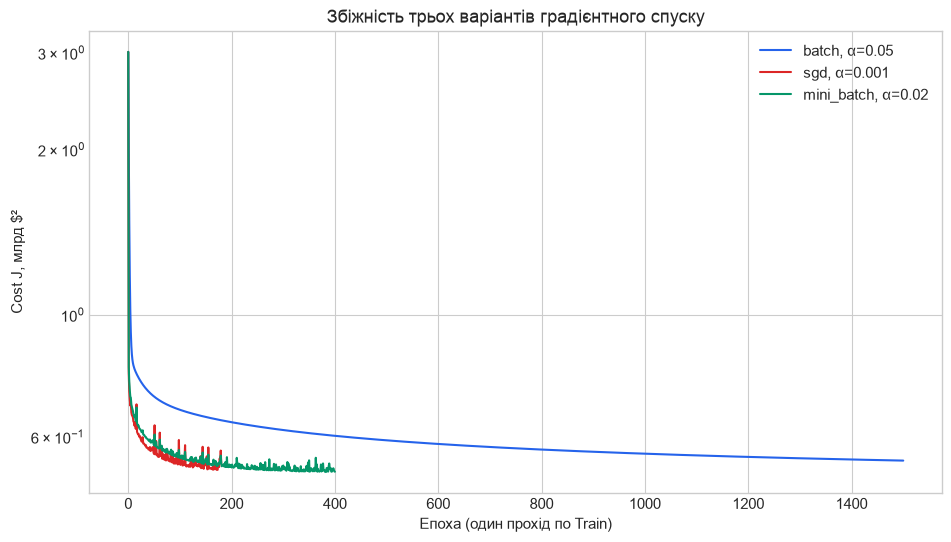

Час навчання та кількість епох:


,seconds,epochs
batch,0.059,1500
sgd,1.182,180
mini_batch,0.108,400


In [11]:
final_epochs = {"batch": 1500, "sgd": 180, "mini_batch": 400}
models = {}
training_times = {}

for optimizer in ["batch", "sgd", "mini_batch"]:
    model = NumpyLinearRegression(
        learning_rate=best_learning_rates[optimizer],
        max_epochs=final_epochs[optimizer],
        optimizer=optimizer,
        batch_size=32,
        tol=1e-9,
        patience=40,
        random_state=SEED,
    )
    started = perf_counter()
    model.fit(X_train_np, y_train_np)
    training_times[optimizer] = perf_counter() - started
    models[optimizer] = model

fig, ax = plt.subplots(figsize=(11, 6))
colors = {"batch": "#2563eb", "sgd": "#dc2626", "mini_batch": "#059669"}
for name, model in models.items():
    ax.plot(
        np.arange(len(model.history_)),
        np.asarray(model.history_) / 1e9,
        label=f"{name}, α={model.learning_rate:g}",
        color=colors[name],
    )
ax.set(
    title="Збіжність трьох варіантів градієнтного спуску",
    xlabel="Епоха (один прохід по Train)",
    ylabel="Cost J, млрд $²",
)
ax.set_yscale("log")
ax.legend()
plt.show()

print("Час навчання та кількість епох:")
display(
    pd.DataFrame(
        {
            "seconds": training_times,
            "epochs": {name: model.n_epochs_ for name, model in models.items()},
        }
    )
)

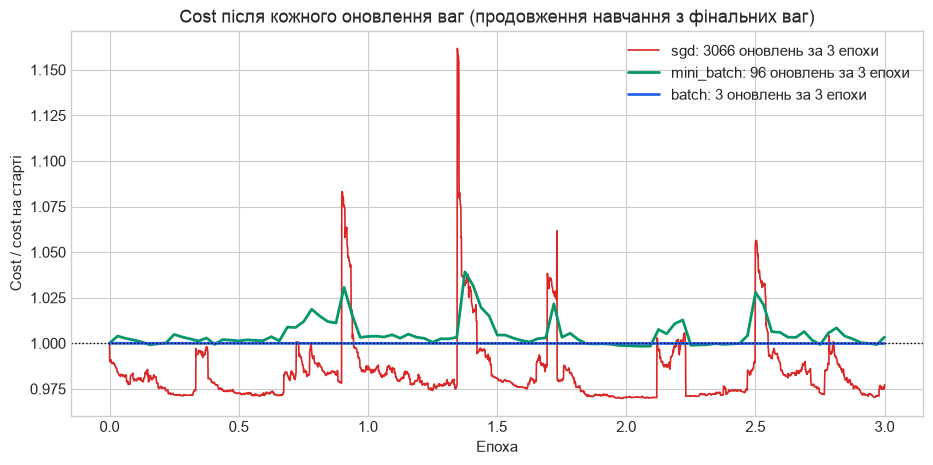

,оновлень за епоху,max cost / стартовий,min cost / стартовий,"розмах коливань, %"
optimizer,,,,
sgd,1022,1.162,0.970,19.200
mini_batch,32,1.039,0.998,4.082
batch,1,1.000,1.000,0.013


In [12]:
def costs_after_each_update(optimizer, n_epochs=3, batch_size=32):
    trained = models[optimizer]
    probe = NumpyLinearRegression(
        learning_rate=trained.learning_rate,
        optimizer=optimizer,
        batch_size=batch_size,
        random_state=SEED,
    )
    probe.w_ = trained.w_.copy()
    probe.b_ = float(trained.b_)
    rng = np.random.default_rng(SEED)
    m = X_train_np.shape[0]
    step = {"batch": m, "sgd": 1, "mini_batch": batch_size}[optimizer]
    start_cost = probe.cost(y_train_np, probe.predict(X_train_np))
    positions, costs = [0.0], [1.0]
    for epoch in range(n_epochs):
        order = rng.permutation(m)
        for start in range(0, m, step):
            indices = order[start:start + step]
            probe._update(X_train_np[indices], y_train_np[indices])
            positions.append(epoch + min(start + step, m) / m)
            costs.append(probe.cost(y_train_np, probe.predict(X_train_np)) / start_cost)
    return np.asarray(positions), np.asarray(costs)


fig, ax = plt.subplots(figsize=(11, 5))
fluctuation_rows = []
for name in ["sgd", "mini_batch", "batch"]:
    positions, relative_costs = costs_after_each_update(name)
    ax.plot(positions, relative_costs, color=colors[name], lw=1.2 if name == "sgd" else 2,
            label=f"{name}: {len(relative_costs) - 1} оновлень за 3 епохи")
    fluctuation_rows.append({
        "optimizer": name,
        "оновлень за епоху": (len(relative_costs) - 1) // 3,
        "max cost / стартовий": relative_costs.max(),
        "min cost / стартовий": relative_costs.min(),
        "розмах коливань, %": 100 * (relative_costs.max() - relative_costs.min()),
    })
ax.axhline(1.0, color="black", ls=":", lw=1)
ax.set(
    title="Cost після кожного оновлення ваг (продовження навчання з фінальних ваг)",
    xlabel="Епоха",
    ylabel="Cost / cost на старті",
)
ax.legend()
plt.show()
display(pd.DataFrame(fluctuation_rows).set_index("optimizer").round(4))

### Аналіз поведінки оптимізаторів

**Який метод збігається найстабільніше.** Batch GD. На першому графіку його крива гладка й монотонна, а на другому три оновлення з фінальних ваг змінюють cost лише на 0.013%. Проте одне оновлення за епоху робить його найповільнішим за епохами: навіть після 1500 епох cost (≈ 0.55 млрд $²) ще повільно спадає й лишається вищим, ніж у SGD та Mini-batch після 180 і 400 епох. За часом Batch GD при цьому найшвидший (див. таблицю вище), бо кожна епоха — одна матрична операція.

**Який метод має найбільші коливання.** SGD. Оновлення за одним об'єктом дає дуже шумну оцінку градієнта. Навіть біля мінімуму cost після окремих кроків коливається від 0.97 до 1.16 стартового значення, тобто розмах становить 19%. Різкі стрибки на другому графіку — кроки на будинках-викидах із великою помилкою: в MSE такий об'єкт має квадратичну вагу й одним кроком відштовхує ваги від мінімуму. Ці коливання видно й на першому графіку як «зубці» червоної кривої, хоча там cost рахується лише раз на епоху.

**Як розмір batch впливає на швидкість і стабільність.** Mini-batch з $B = 32$ усереднює градієнт по 32 об'єктах. Дисперсія оцінки градієнта при цьому зменшується приблизно в $B$ разів, і розмах коливань падає з 19% до 4%. Водночас за епоху виконується 32 оновлення, а не одне. Тому за 400 епох Mini-batch досягає найнижчого cost серед трьох методів і найкращих Train та Test $R^2$ (0.828 і 0.839). Більший batch дає стабільніший, але рідший і дорожчий крок (межа — Batch GD), менший — частіші, але шумніші кроки (межа — SGD). Векторизований Mini-batch також у кілька разів швидший за SGD, який робить 1022 окремі Python-кроки за епоху.

**Як learning rate впливає на збіжність.** У межах сітки більший $\alpha$ кращий для всіх трьох методів. Для Batch GD Validation $R^2$ зростає з 0.858 ($\alpha = 0.01$) до 0.881 ($\alpha = 0.05$), для SGD — з 0.873 до 0.888, для Mini-batch — з 0.882 до 0.887. Малий $\alpha$ дає замалі кроки, і за фіксований бюджет епох модель не доходить до мінімуму. Допустимий $\alpha$ тим менший, чим шумніший градієнт: оптимальне для SGD $\alpha = 0.001$ у 50 разів менше, ніж для Batch GD (0.05). Причина в тому, що кожен крок SGD спрямований за одним об'єктом, і великий $\alpha$ розгойдує ваги (див. стрибки вище). Надто великий $\alpha$ для будь-якого методу означає перескакування мінімуму й розбіжність. Це видно в експерименті A: без масштабування $\alpha = 10^{-8}$ уже гірший за $5 \cdot 10^{-9}$ (Validation $R^2$ 0.544 проти 0.705).

## 7. Метрики якості: $R^2$, RMSE та MAE

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

$R^2$ — частка варіації цілі, яку пояснює модель відносно константного прогнозу
$\bar y$. Значення 1 є ідеальним, 0 означає якість рівня прогнозу середнім, а
від'ємне значення можливе, якщо модель гірша за цей простий baseline.

In [13]:
datasets = {
    "Train": (X_train_np, y_train_np),
    "Validation": (X_val_np, y_val_np),
    "Test": (X_test_np, y_test_np),
}

metric_rows = []
for optimizer, model in models.items():
    for split_name, (features, target) in datasets.items():
        prediction = model.predict(features)
        metric_rows.append(
            {
                "optimizer": optimizer,
                "split": split_name,
                "R2": r2_score_numpy(target, prediction),
                "RMSE_$": rmse_numpy(target, prediction),
                "MAE_$": mae_numpy(target, prediction),
            }
        )

metrics = pd.DataFrame(metric_rows)
display(metrics.pivot(index="optimizer", columns="split", values="R2").round(4))
display(metrics.round({"R2": 4, "RMSE_$": 0, "MAE_$": 0}))

validation_scores = metrics.query("split == 'Validation'").set_index("optimizer")["R2"]
best_optimizer = validation_scores.idxmax()
best_model = models[best_optimizer]

train_r2 = metrics.query("optimizer == @best_optimizer and split == 'Train'")["R2"].iloc[0]
test_r2 = metrics.query("optimizer == @best_optimizer and split == 'Test'")["R2"].iloc[0]
gap = train_r2 - test_r2

print(f"Найкращий метод за Validation R²: {best_optimizer}")
print(f"Train R²={train_r2:.4f}; Test R²={test_r2:.4f}; gap={gap:.4f}")
if gap > 0.10:
    print("Висновок: помітний розрив Train–Test вказує на перенавчання.")
elif test_r2 < 0.60:
    print("Висновок: модель недонавчена або лінійних ознак недостатньо.")
else:
    print("Висновок: якість на Train і Test узгоджена; узагальнення прийнятне.")

split,Test,Train,Validation
optimizer,,,
batch,0.820,0.820,0.889
mini_batch,0.839,0.828,0.885
sgd,0.810,0.822,0.874


,optimizer,split,R2,RMSE_$,MAE_$
0,batch,Train,0.820,"32,942.000","20,235.000"
1,batch,Validation,0.889,"26,415.000","19,315.000"
2,batch,Test,0.820,"37,038.000","21,887.000"
3,sgd,Train,0.822,"32,753.000","20,456.000"
4,sgd,Validation,0.874,"28,103.000","20,268.000"
5,sgd,Test,0.810,"37,987.000","21,903.000"
6,mini_batch,Train,0.828,"32,186.000","19,993.000"
7,mini_batch,Validation,0.885,"26,922.000","19,568.000"
8,mini_batch,Test,0.839,"34,969.000","21,172.000"


Найкращий метод за Validation R²: batch
Train R²=0.8197; Test R²=0.8197; gap=-0.0000
Висновок: якість на Train і Test узгоджена; узагальнення прийнятне.


## 8. Перевірка статистичних припущень

Діагностика виконується за **залишками Train** найкращої за Validation моделі:
$\varepsilon=y-\hat y$. Це не є ще одним етапом підбору за Test.

1. Лінійність: Residuals vs Fitted та середні залишки у децилях прогнозу.
2. Нормальність: Q-Q plot і тест Шапіро–Уїлка.
3. Гомоскедастичність: Scale-Location і кореляція Спірмена між
   $|\varepsilon|$ та fitted.
4. Мультиколінеарність: VIF; орієнтири 5 (увага) та 10 (суттєва проблема).

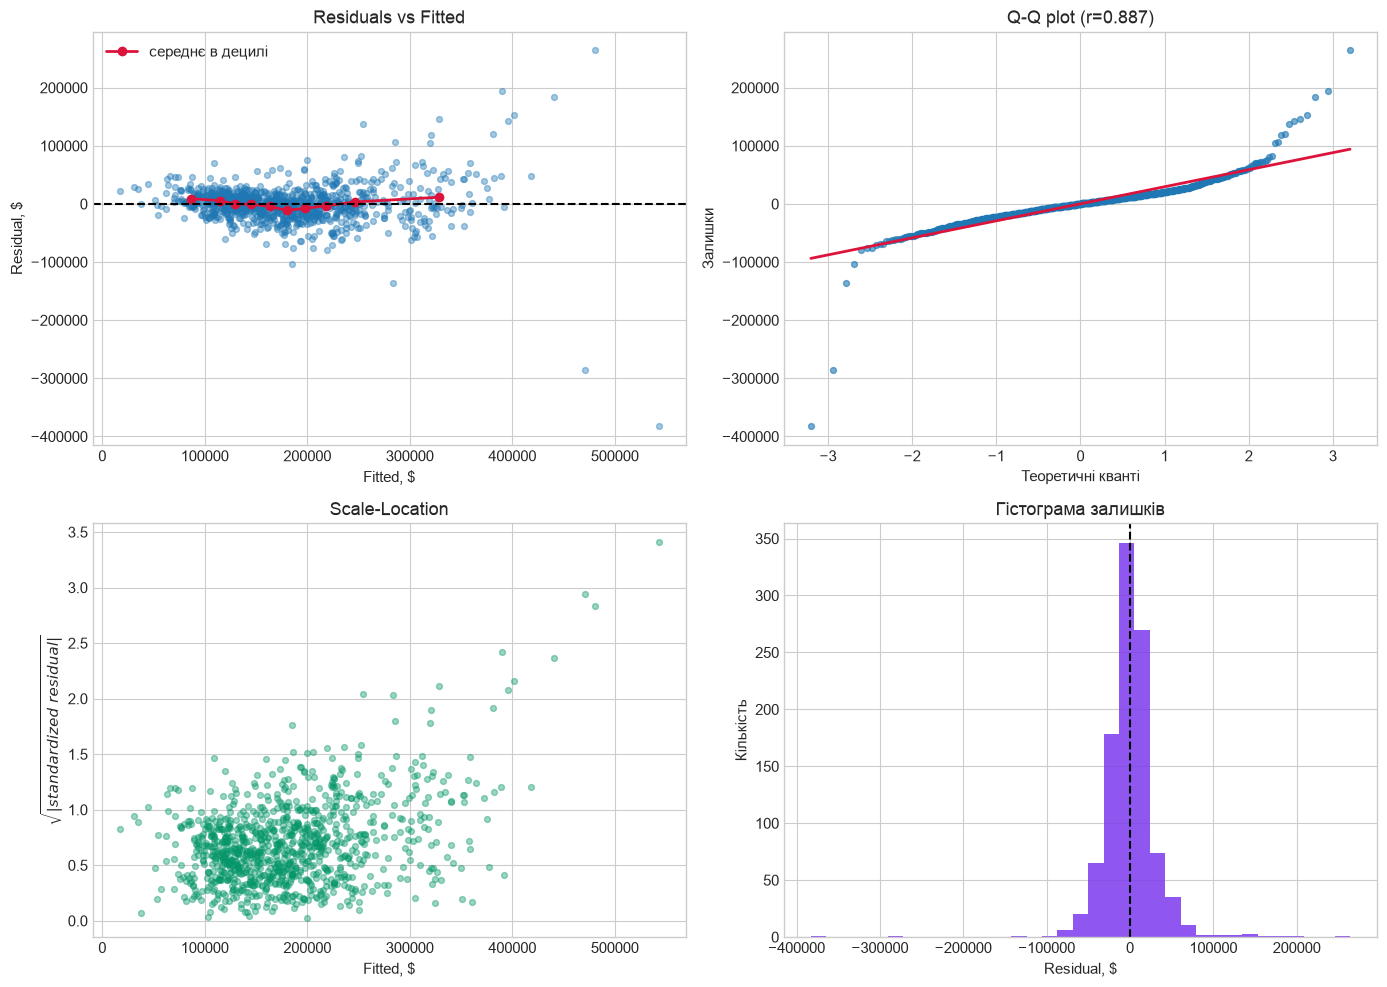

In [14]:
fitted = best_model.predict(X_train_np)
residuals = y_train_np - fitted
standardized_residuals = residuals / residuals.std(ddof=1)

diagnostic_frame = pd.DataFrame({"fitted": fitted, "residual": residuals})
diagnostic_frame["fitted_bin"] = pd.qcut(
    diagnostic_frame["fitted"], q=10, duplicates="drop"
)
binned_residuals = diagnostic_frame.groupby(
    "fitted_bin", observed=False
).agg(fitted_mean=("fitted", "mean"), residual_mean=("residual", "mean"))

(theoretical_q, ordered_residuals), (qq_slope, qq_intercept, qq_r) = stats.probplot(
    residuals, dist="norm"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(fitted, residuals, alpha=0.4, s=18)
axes[0, 0].plot(
    binned_residuals["fitted_mean"], binned_residuals["residual_mean"],
    color="crimson", marker="o", lw=2, label="середнє в децилі"
)
axes[0, 0].axhline(0, color="black", ls="--")
axes[0, 0].set(title="Residuals vs Fitted", xlabel="Fitted, $", ylabel="Residual, $")
axes[0, 0].legend()

axes[0, 1].scatter(theoretical_q, ordered_residuals, alpha=0.6, s=18)
axes[0, 1].plot(
    theoretical_q,
    qq_slope * theoretical_q + qq_intercept,
    color="crimson",
    lw=2,
)
axes[0, 1].set(title=f"Q-Q plot (r={qq_r:.3f})", xlabel="Теоретичні кванті", ylabel="Залишки")

scale_location = np.sqrt(np.abs(standardized_residuals))
axes[1, 0].scatter(fitted, scale_location, alpha=0.4, s=18, color="#059669")
axes[1, 0].set(
    title="Scale-Location", xlabel="Fitted, $", ylabel=r"$\sqrt{|standardized\ residual|}$"
)

axes[1, 1].hist(residuals, bins=35, color="#7c3aed", alpha=0.85)
axes[1, 1].axvline(0, color="black", ls="--")
axes[1, 1].set(title="Гістограма залишків", xlabel="Residual, $", ylabel="Кількість")

fig.tight_layout()
plt.show()

In [15]:
def variance_inflation_factors(X, names):
    '''Compute VIF through auxiliary least-squares regressions.'''
    X = np.asarray(X, dtype=float)
    rows = []
    for column_index, name in enumerate(names):
        target_column = X[:, column_index]
        other_columns = np.delete(X, column_index, axis=1)
        design = np.column_stack([np.ones(X.shape[0]), other_columns])
        coefficients, *_ = np.linalg.lstsq(design, target_column, rcond=None)
        prediction = design @ coefficients
        denominator = np.sum((target_column - target_column.mean()) ** 2)
        r2_aux = 1.0 - np.sum((target_column - prediction) ** 2) / denominator
        vif = np.inf if r2_aux >= 1.0 - 1e-12 else 1.0 / (1.0 - r2_aux)
        rows.append({"feature": name, "VIF": vif})
    return pd.DataFrame(rows).sort_values("VIF", ascending=False)


vif_table = variance_inflation_factors(X_train_np, feature_names)
display(vif_table.head(15))

shapiro_w, shapiro_p = stats.shapiro(residuals)
hetero_rho, hetero_p = stats.spearmanr(np.abs(residuals), fitted)
linearity_ratio = (
    binned_residuals["residual_mean"].abs().max() / residuals.std(ddof=1)
)
max_vif = vif_table["VIF"].replace(np.inf, np.nan).max()

print("ПІДСУМКОВІ ДІАГНОСТИЧНІ ВИСНОВКИ")
print(
    f"1. Лінійність: max |середнього залишку в децилі| / SD = {linearity_ratio:.3f}. "
    + ("Явного систематичного вигину мало." if linearity_ratio < 0.25
       else "Помітна структура залишків: припущення виконується не повністю.")
)
print(
    f"2. Нормальність: Shapiro W={shapiro_w:.4f}, p={shapiro_p:.3g}. "
    + ("Немає підстав відхиляти нормальність." if shapiro_p >= 0.05
       else "Нормальність відхиляється; хвости/викиди видно на Q-Q plot.")
)
print(
    f"3. Гомоскедастичність: Spearman(|residual|, fitted)={hetero_rho:.3f}, p={hetero_p:.3g}. "
    + ("Сильного зв'язку дисперсії з рівнем прогнозу не виявлено." if abs(hetero_rho) < 0.15
       else "Розкид залежить від рівня прогнозу: гомоскедастичність порушена.")
)
print(
    f"4. Мультиколінеарність: максимальний скінченний VIF={max_vif:.2f}. "
    + ("Суттєвої проблеми за порогом 5 немає." if max_vif < 5
       else "Є корельовані предиктори; окремі коефіцієнти можуть бути нестабільними.")
)
print(
    "Наслідок мультиколінеарності: прогноз може залишатися якісним, але знак і величина "
    "окремого коефіцієнта стають чутливими до складу вибірки; для стабілізації "
    "доречні вилучення дублюючих ознак або Ridge-регуляризація."
)

,feature,VIF
42,ExterQual_TA,14.550
21,Neighborhood_NAmes,13.061
41,ExterQual_Gd,11.523
39,KitchenQual_TA,10.038
26,Neighborhood_OldTown,9.537
36,BsmtQual_TA,8.848
14,Neighborhood_CollgCr,8.328
38,KitchenQual_Gd,7.792
16,Neighborhood_Edwards,7.628
8,YearBuilt,6.595


ПІДСУМКОВІ ДІАГНОСТИЧНІ ВИСНОВКИ
1. Лінійність: max |середнього залишку в децилі| / SD = 0.349. Помітна структура залишків: припущення виконується не повністю.
2. Нормальність: Shapiro W=0.7943, p=4.75e-34. Нормальність відхиляється; хвости/викиди видно на Q-Q plot.
3. Гомоскедастичність: Spearman(|residual|, fitted)=0.227, p=2.19e-13. Розкид залежить від рівня прогнозу: гомоскедастичність порушена.
4. Мультиколінеарність: максимальний скінченний VIF=14.55. Є корельовані предиктори; окремі коефіцієнти можуть бути нестабільними.
Наслідок мультиколінеарності: прогноз може залишатися якісним, але знак і величина окремого коефіцієнта стають чутливими до складу вибірки; для стабілізації доречні вилучення дублюючих ознак або Ridge-регуляризація.


### Висновки щодо статистичних припущень

1. **Лінійність.** Припущення **виконується лише частково**, тому що середні залишки в децилях прогнозу не лежать на нулі. Максимальне відхилення становить 0.35 SD залишків, а крива має U-подібну форму: для найдешевших і найдорожчих будинків модель систематично занижує ціну (залишки > 0), а в середньому діапазоні — завищує. Це означає, що залежність ціни від ознак частково нелінійна (ціна зростає з площею та якістю швидше за лінійно). Прогнози на краях діапазону зміщені, і модель виграла б від логарифмування `SalePrice` або нелінійних ознак.

2. **Нормальність залишків.** Припущення **порушується**, тому що тест Шапіро–Уїлка відхиляє нормальність ($W = 0.794$, $p \approx 5 \cdot 10^{-34}$). На Q-Q plot обидва хвости відходять від прямої, а на гістограмі видно кілька величезних залишків: до −380 000 $ і +265 000 $. Це означає, що класичні довірчі інтервали й t-тести для коефіцієнтів ненадійні. Сам прогноз при цьому лишається придатним, але чутливим до викидів: у MSE вони мають квадратичну вагу.

3. **Гомоскедастичність.** Припущення **порушується**, тому що на графіку Scale-Location розкид $\sqrt{|\text{standardized residual}|}$ зростає разом із прогнозом, а кореляція Спірмена між $|\varepsilon|$ та fitted значуща ($\rho = 0.23$, $p \approx 2 \cdot 10^{-13}$). Це означає, що для дорогих будинків помилка в доларах значно більша, ніж для дешевих (гетероскедастичність «віялом»). Стандартні похибки коефіцієнтів через це занижені; доречні робастні оцінки похибок або перехід до $\log(\text{SalePrice})$.

4. **Відсутність мультиколінеарності.** Припущення **порушується помірно**, тому що максимальний VIF = 14.6: щонайменше 15 ознак мають VIF > 5, з них 4 — понад 10. Найвищі VIF мають не числові пари, а dummy-змінні якості (`ExterQual`, `KitchenQual`, `BsmtQual`) і великих районів (`Neighborhood_NAmes`). Оцінки якості різних частин будинку сильно корелюють між собою, а великий район — з базовою категорією. Серед числових ознак VIF 5.5–6.6 мають `GrLivArea`, `GarageCars`, `GarageArea` і `YearBuilt`. Це означає, що окремі коефіцієнти можуть бути нестабільними; наскільки саме — перевіряємо нижче.

In [16]:
coefficient_table = pd.DataFrame(
    {"feature": feature_names, "coefficient_$": best_model.w_}
)
coefficient_table["abs_coefficient"] = coefficient_table["coefficient_$"].abs()
display(coefficient_table.sort_values("abs_coefficient", ascending=False).head(15))

print(
    "Інтерпретація: для стандартизованої числової ознаки коефіцієнт — зміна "
    "прогнозованої ціни при збільшенні ознаки на 1 стандартне відхилення за "
    "інших рівних умов. Для OHE — різниця відносно вилученої базової категорії."
)

,feature,coefficient_$,abs_coefficient
24,Neighborhood_NoRidge,"42,500.451","42,500.451"
31,Neighborhood_StoneBr,"32,589.237","32,589.237"
25,Neighborhood_NridgHt,"26,053.383","26,053.383"
35,BsmtQual_Gd,"-25,994.651","25,994.651"
15,Neighborhood_Crawfor,"24,647.927","24,647.927"
39,KitchenQual_TA,"-22,468.054","22,468.054"
36,BsmtQual_TA,"-22,410.986","22,410.986"
0,OverallQual,"20,751.037","20,751.037"
1,GrLivArea,"19,648.663","19,648.663"
11,Neighborhood_BrDale,"-16,202.765","16,202.765"


Інтерпретація: для стандартизованої числової ознаки коефіцієнт — зміна прогнозованої ціни при збільшенні ознаки на 1 стандартне відхилення за інших рівних умов. Для OHE — різниця відносно вилученої базової категорії.


,"w перша, повна модель","w друга, повна модель","сума двох, повна модель","w перша, без другої"
пара (r на Train),,,,
GrLivArea / TotRmsAbvGrd (0.82),"19,649.000","2,056.000","21,704.000","22,130.000"
GarageCars / GarageArea (0.88),"9,557.000",202.000,"9,759.000","9,998.000"
TotalBsmtSF / 1stFlrSF (0.83),"2,319.000","3,690.000","6,009.000","4,767.000"


Validation R²: повна модель = 0.8889, без ['TotRmsAbvGrd', 'GarageArea', '1stFlrSF'] = 0.8892


,"w, повна модель","bootstrap std, повна","bootstrap std, без дублікатів","частка змін знака, повна",у корельованій парі
OverallQual,"20,751.037","1,795.028","1,867.071",0.000,False
GrLivArea,"19,648.663","7,791.913","5,330.457",0.000,True
GarageCars,"9,557.035","6,181.238","2,476.052",0.133,True
GarageArea,202.386,"5,621.890",NaN,0.500,True
TotalBsmtSF,"2,319.181","5,000.348","4,087.384",0.267,True
1stFlrSF,"3,689.808","2,527.798",NaN,0.133,True
FullBath,-451.367,"2,672.211","3,145.733",0.400,False
TotRmsAbvGrd,"2,055.523","3,946.559",NaN,0.300,True
YearBuilt,"11,170.509","2,677.373","2,878.099",0.000,False
LotArea,"7,759.198","1,695.035","1,770.053",0.000,False


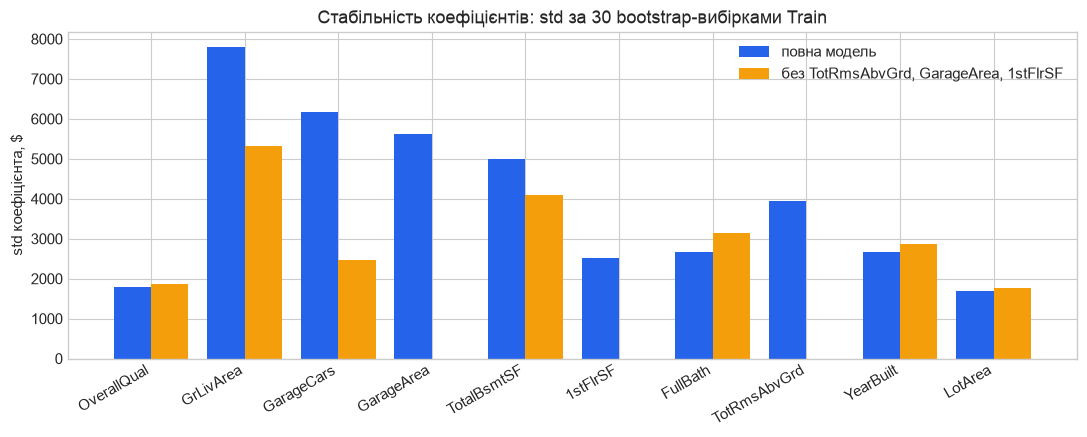

In [17]:
correlated_pairs = [(first, second) for first, second, _ in strong_pairs]
duplicate_features = [second for _, second in correlated_pairs]
keep_mask = ~np.isin(feature_names, duplicate_features)
reduced_names = feature_names[keep_mask]


def fit_batch(X_matrix, y_vector):
    return NumpyLinearRegression(
        learning_rate=best_learning_rates["batch"],
        max_epochs=final_epochs["batch"],
        optimizer="batch",
        tol=1e-9,
        patience=40,
        random_state=SEED,
    ).fit(X_matrix, y_vector)


full_model = fit_batch(X_train_np, y_train_np)
reduced_model = fit_batch(X_train_np[:, keep_mask], y_train_np)
full_w = pd.Series(full_model.w_, index=feature_names)
reduced_w = pd.Series(reduced_model.w_, index=reduced_names)

pair_table = pd.DataFrame([
    {
        "пара (r на Train)": f"{first} / {second} ({train_corr.loc[first, second]:.2f})",
        "w перша, повна модель": full_w[first],
        "w друга, повна модель": full_w[second],
        "сума двох, повна модель": full_w[first] + full_w[second],
        "w перша, без другої": reduced_w[first],
    }
    for first, second in correlated_pairs
]).set_index("пара (r на Train)")
display(pair_table.round(0))

print(f"Validation R²: повна модель = {r2_score_numpy(y_val_np, full_model.predict(X_val_np)):.4f}, "
      f"без {duplicate_features} = {r2_score_numpy(y_val_np, reduced_model.predict(X_val_np[:, keep_mask])):.4f}")

bootstrap_rng = np.random.default_rng(SEED)
bootstrap_full, bootstrap_reduced = [], []
for _ in range(30):
    sample = bootstrap_rng.integers(0, len(y_train_np), len(y_train_np))
    bootstrap_full.append(fit_batch(X_train_np[sample], y_train_np[sample]).w_)
    bootstrap_reduced.append(fit_batch(X_train_np[sample][:, keep_mask], y_train_np[sample]).w_)
bootstrap_full = pd.DataFrame(bootstrap_full, columns=feature_names)
bootstrap_reduced = pd.DataFrame(bootstrap_reduced, columns=reduced_names)

paired_features = [feature for pair in correlated_pairs for feature in pair]
stability = pd.DataFrame({
    "w, повна модель": full_w[selected_numeric],
    "bootstrap std, повна": bootstrap_full[selected_numeric].std(),
    "bootstrap std, без дублікатів": bootstrap_reduced.reindex(columns=selected_numeric).std(),
    "частка змін знака, повна": (np.sign(bootstrap_full[selected_numeric]) != np.sign(full_w[selected_numeric])).mean(),
})
stability["у корельованій парі"] = stability.index.isin(paired_features)
display(stability.round(3))

fig, ax = plt.subplots(figsize=(11, 4.5))
positions = np.arange(len(selected_numeric))
ax.bar(positions - 0.2, stability["bootstrap std, повна"], width=0.4, color="#2563eb", label="повна модель")
ax.bar(positions + 0.2, stability["bootstrap std, без дублікатів"].fillna(0), width=0.4, color="#f59e0b",
       label=f"без {', '.join(duplicate_features)}")
ax.set_xticks(positions, selected_numeric, rotation=30, ha="right")
ax.set(title="Стабільність коефіцієнтів: std за 30 bootstrap-вибірками Train", ylabel="std коефіцієнта, $")
ax.legend()
plt.tight_layout()
plt.show()

### Чи вплинула мультиколінеарність на коефіцієнти

**Так — на інтерпретацію та стабільність, але не на якість прогнозу.**

- **Розподіл ефекту між «близнюками».** У повній моделі ефект гаража майже повністю дістався `GarageCars` (9 557 $ на 1 SD), а `GarageArea` отримала лише 202 $. Ефект житлової площі розділено як 19 649 $ (`GrLivArea`) + 2 056 $ (`TotRmsAbvGrd`), для підвалу та першого поверху — 2 319 $ + 3 690 $. Якщо прибрати одну ознаку з пари, друга забирає майже всю суму: `GrLivArea` — 22 130 $ (сума пари в повній моделі 21 704 $), `GarageCars` — 9 998 $ (9 759 $), `TotalBsmtSF` — 4 767 $ (6 009 $). Отже, коефіцієнт корельованої ознаки не можна трактувати як «ефект цієї ознаки за інших рівних умов»: модель довільно ділить спільний внесок пари.
- **Нестабільність.** На 30 bootstrap-вибірках Train коефіцієнт `GarageArea` змінює знак у 50% випадків, `TotRmsAbvGrd` — у 30%, `TotalBsmtSF` — у 27%. Їхні std (3 900–5 600 $) перевищують самі коефіцієнти. Ознаки поза парами (`OverallQual`, `YearBuilt`, `LotArea`) не змінюють знак жодного разу, а їхні std (1 700–2 900 $) після вилучення дублікатів майже не змінюються. Натомість для ознак, у яких прибрали «близнюка», std різко падає: `GarageCars` — у 2.5 раза (6 181 → 2 476 $), `GrLivArea` — з 7 792 до 5 330 $. Окремо показовий `FullBath`: його коефіцієнт від'ємний (−451 $) і змінює знак у 40% вибірок. Висновок «більше ванних кімнат — нижча ціна» є артефактом кореляції з площею, а не реальним ефектом.
- **Прогноз.** Validation $R^2$ практично однаковий: 0.8889 з усіма ознаками і 0.8892 без трьох дублікатів. Мультиколінеарність не шкодить точності — вона робить окремі ваги неінтерпретованими.

**Практичний висновок:** для прогнозу можна залишити всі ознаки. Для інтерпретації коефіцієнтів краще прибрати дублікати або застосувати Ridge-регуляризацію, яка стабілізує ваги корельованих ознак.

## 9. Експеримент A: вплив масштабування

Порівнюємо один і той самий Mini-batch GD на тих самих ознаках:

1. числові ознаки залишено в сирих одиницях;
2. числові ознаки стандартизовано.

Для кожного варіанта $\alpha$ підбирається лише за Validation. Без
масштабування поверхня MSE витягнута: напрямки `LotArea`, `GrLivArea`, роки та
бінарні dummy-змінні мають дуже різну кривизну. Один великий крок розходиться,
а безпечний малий крок дуже повільний в інших напрямках. Стандартизація робить
лінії рівня ближчими до кіл, тому дозволяє більший і стабільніший крок.

,learning_rate,validation_R2
0,1.00e-10,0.153
1,5.00e-10,0.413
2,1.00e-09,0.543
3,5.00e-09,0.705
4,1.00e-08,0.544


Найкращий α без масштабування: 5e-09
α зі стандартизацією: 0.02


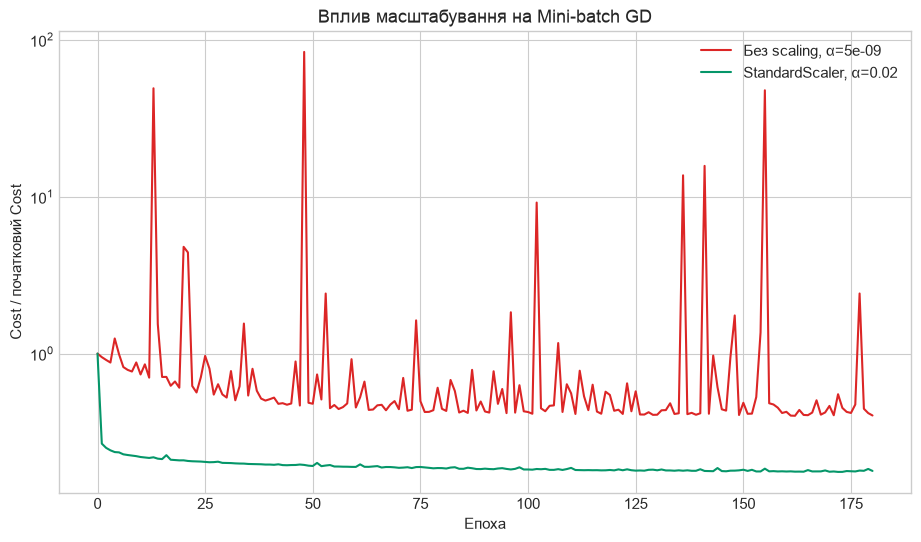

,variant,learning_rate,Validation_R2,final_relative_cost
0,raw numerical features,5e-09,0.705,0.403
1,standardized numerical features,0.02,0.881,0.179


Висновок експерименту: стандартизація допускає learning rate на багато порядків більший і швидше зменшує cost; без неї стабільний крок обмежує ознака з найбільшим масштабом.


In [18]:
raw_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), selected_numeric),
        (
            "cat",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    (
                        "onehot",
                        OneHotEncoder(
                            drop="first", handle_unknown="ignore",
                            sparse_output=False, dtype=float
                        ),
                    ),
                ]
            ),
            selected_categorical,
        ),
    ],
    verbose_feature_names_out=False,
)

X_train_raw = raw_preprocessor.fit_transform(X_train[selected_features])
X_val_raw = raw_preprocessor.transform(X_val[selected_features])

raw_rate_rows = []
raw_models = {}
for rate in [1e-10, 5e-10, 1e-9, 5e-9, 1e-8]:
    candidate = NumpyLinearRegression(
        learning_rate=rate,
        max_epochs=180,
        optimizer="mini_batch",
        batch_size=32,
        tol=0.0,
        random_state=SEED,
    ).fit(X_train_raw, y_train_np)
    score = r2_score_numpy(y_val_np, candidate.predict(X_val_raw))
    raw_rate_rows.append({"learning_rate": rate, "validation_R2": score})
    raw_models[rate] = candidate

raw_rate_results = pd.DataFrame(raw_rate_rows)
best_raw_rate = raw_rate_results.loc[raw_rate_results["validation_R2"].idxmax(), "learning_rate"]
raw_model = raw_models[best_raw_rate]

scaled_model_for_experiment = NumpyLinearRegression(
    learning_rate=best_learning_rates["mini_batch"],
    max_epochs=180,
    optimizer="mini_batch",
    batch_size=32,
    tol=0.0,
    random_state=SEED,
).fit(X_train_np, y_train_np)

raw_rate_display = raw_rate_results.copy()
raw_rate_display["learning_rate"] = raw_rate_display["learning_rate"].map(
    lambda value: f"{value:.2e}"
)
display(raw_rate_display)
print(f"Найкращий α без масштабування: {best_raw_rate:g}")
print(f"α зі стандартизацією: {best_learning_rates['mini_batch']:g}")

fig, ax = plt.subplots(figsize=(11, 6))
raw_history = np.asarray(raw_model.history_, dtype=float)
scaled_history = np.asarray(scaled_model_for_experiment.history_, dtype=float)
ax.plot(
    np.arange(len(raw_history)),
    raw_history / raw_history[0],
    label=f"Без scaling, α={best_raw_rate:g}",
    color="#dc2626",
)
ax.plot(
    np.arange(len(scaled_history)),
    scaled_history / scaled_history[0],
    label=f"StandardScaler, α={best_learning_rates['mini_batch']:g}",
    color="#059669",
)
ax.set(
    title="Вплив масштабування на Mini-batch GD",
    xlabel="Епоха",
    ylabel="Cost / початковий Cost",
)
ax.set_yscale("log")
ax.legend()
plt.show()

scaling_comparison = pd.DataFrame(
    [
        {
            "variant": "raw numerical features",
            "learning_rate": best_raw_rate,
            "Validation_R2": r2_score_numpy(y_val_np, raw_model.predict(X_val_raw)),
            "final_relative_cost": raw_history[-1] / raw_history[0],
        },
        {
            "variant": "standardized numerical features",
            "learning_rate": best_learning_rates["mini_batch"],
            "Validation_R2": r2_score_numpy(
                y_val_np, scaled_model_for_experiment.predict(X_val_np)
            ),
            "final_relative_cost": scaled_history[-1] / scaled_history[0],
        },
    ]
)
scaling_display = scaling_comparison.copy()
scaling_display["learning_rate"] = scaling_display["learning_rate"].map(
    lambda value: f"{value:.3g}"
)
display(scaling_display)
print(
    "Висновок експерименту: стандартизація допускає learning rate на багато "
    "порядків більший і швидше зменшує cost; без неї стабільний крок обмежує "
    "ознака з найбільшим масштабом."
)

## 10. Відповіді на ключові теоретичні питання

1. **Чому split робиться до preprocessing?** Щоб статистики Validation/Test не
   потрапили в медіани, середні, стандартні відхилення, набір категорій або
   відбір ознак. Інакше виникає data leakage.
2. **Що робити з новими категоріями?** `handle_unknown='ignore'` не створює новий
   стовпець під час inference і кодує невідому категорію нулями у її OHE-блоці.
   Розмірність залишається тією самою, що на Train.
3. **Чому не Ordinal/Target Encoding?** Для `Neighborhood` чи `HouseStyle`
   природного порядку немає. Target Encoding потребує особливо обережної
   out-of-fold реалізації, інакше легко внести leakage.
4. **Що означає від'ємний $R^2$?** Сума квадратів помилок моделі більша, ніж у
   константного прогнозу середнім значенням цілі на оцінюваній вибірці.
5. **Який GD стабільніший?** Batch — найгладший; SGD — найшумніший; Mini-batch —
   практичний компроміс. Збільшення batch зменшує шум, але робить крок дорожчим
   і рідшим.
6. **Навіщо bias $b$?** Він дозволяє гіперплощині не проходити через початок
   координат; тут ініціалізація $b=\bar y_{train}$ пришвидшує старт.
7. **Чи гарантує хороший $R^2$ виконання припущень?** Ні. Можна добре прогнозувати
   та водночас мати ненормальні/гетероскедастичні залишки чи нестабільні через
   мультиколінеарність коефіцієнти.

## Підсумок

Робота реалізує повний pipeline без витоку даних, три алгоритми градієнтного
спуску та статистичну діагностику. Для захисту важливо розрізняти **якість
прогнозу** (R²/RMSE/MAE), **поведінку оптимізатора** (cost vs epochs) і
**коректність статистичної інтерпретації** (залишки та VIF).

In [19]:
test_row = metrics.query("optimizer == @best_optimizer and split == 'Test'").iloc[0]
print("ФІНАЛЬНИЙ РЕЗУЛЬТАТ")
print(f"Найкращий оптимізатор за Validation: {best_optimizer}")
print(f"Test R²: {test_row['R2']:.4f}")
print(f"Test RMSE: ${test_row['RMSE_$']:,.0f}")
print(f"Test MAE: ${test_row['MAE_$']:,.0f}")
print(f"Кількість ознак після preprocessing: {X_train_np.shape[1]}")
print("Усі ключові етапи практичного завдання виконано.")

ФІНАЛЬНИЙ РЕЗУЛЬТАТ
Найкращий оптимізатор за Validation: batch
Test R²: 0.8197
Test RMSE: $37,038
Test MAE: $21,887
Кількість ознак після preprocessing: 43
Усі ключові етапи практичного завдання виконано.
